<div style="text-align: center;">

  <img src="img/LogoUesc.png" alt="UESC" style="width: 60px; display: block; margin: 0 auto 5px auto;">

  <div style="font-size: 20px;"><strong>UNIVERSIDADE ESTADUAL DE SANTA CRUZ - UESC</strong></div>
  <div style="font-size: 18px;">DEPARTAMENTO DE ENGENHARIAS E COMPUTAÇÃO - DEC</div>
  <div style="font-size: 18px;">Grupo de Pesquisas em Simulações e Controle de Processos</div>

  <hr style="margin: 20px 0; border: 1px solid #0074B7;">

  <div style="font-size: 22px; font-weight: bold; margin-bottom: 10px;">PROGRAMAÇÃO EM PYTHON PARA AS ENGENHARIAS</div>

  <div style="font-size: 18px; margin-top: 10px;"><strong>Tema</strong>: Instrumentação com Python — Medição, Calibração e Tratamento de Sinais.</div>
  <div style="font-size: 18px;"><strong>Prof.  Dr.  E. R. Edwards</strong></div>

  <div style="font-size: 16px; margin-top: 15px;">Ilhéus - BA, Abril de 2027</div>
  
  <hr style="margin: 20px 0; border: 1px solid #0074B7;">

</div>

**Apresentação**

Instrumentar um processo significa transformar grandezas físicas em informações úteis para observar, interpretar e controlar seu comportamento. Temperatura, pressão, vazão e nível não chegam ao computador como conceitos abstratos: são captados por sensores, convertidos em sinais, transmitidos e amostrados. Cada etapa introduz hipóteses e limitações.

Neste notebook, os exemplos relacionam **fenômeno físico → princípio de medição → equação de conversão → cálculo manual → algoritmo → interpretação**. Trabalhamos com dados sintéticos para fins didáticos; não se trata de procedimentos de calibração certificados ou de projeto de sistemas instrumentados de segurança.

**Objetivos de aprendizagem:** converter sinais industriais, construir curvas de calibração, analisar erros e dispersão, filtrar ruídos, avaliar amostragem, estudar a dinâmica de sensores e interpretar medições de processos químicos.

**Sumário**

1. [Instrumentação, medição e sinais de processos](#secao-1)
2. [Preparação do ambiente computacional](#secao-2)
3. [Grandezas, unidades e amostragem](#secao-3)
4. [Transmissores industriais de 4 a 20 mA](#secao-4)
5. [Calibração linear: sensibilidade e offset](#secao-5)
6. [Erro, exatidão, precisão e incerteza](#secao-6)
7. [Análise estatística de medições repetidas](#secao-7)
8. [Ruído e geração de sinais sintéticos](#secao-8)
9. [Filtragem por média móvel](#secao-9)
10. [Filtragem exponencial de primeira ordem](#secao-10)
11. [Tempo de amostragem e frequência de Nyquist](#secao-11)
12. [Resposta dinâmica de um sensor de temperatura](#secao-12)
13. [Detecção de valores anômalos e falhas](#secao-13)
14. [Controle de processos: referência, medição e erro](#secao-14)
15. [Análise de sinais no domínio da frequência](#secao-15)
16. [Tratamento de dados experimentais com Pandas](#secao-16)
17. [Projeto integrador: supervisão de um tanque aquecido](#secao-17)
18. [Boas práticas e validação de resultados](#secao-18)
19. [Exercícios de consolidação](#secao-19)
20. [Conclusões](#secao-20)

<div id="secao-1" style="background-color:#f1faff; border-left:6px solid #0074B7; color:#003366; border-radius:8px; padding:15px 20px; font-size:20px; font-weight:bold;">1. Instrumentação, medição e sinais de processos</div>

**O problema de Engenharia.** Um sistema de controle não observa diretamente a temperatura ou a pressão: recebe uma representação elétrica ou digital da grandeza. Para interpretar o sinal, precisamos conhecer a faixa calibrada, as unidades, o tempo de resposta e as condições de medição.

**Cadeia de medição:** processo físico → elemento sensor → condicionamento/transmissão → aquisição de dados → tratamento numérico → interpretação. Um gráfico aparentemente suave não garante que a medição seja correta.

<div id="secao-2" style="background-color:#f1faff; border-left:6px solid #0074B7; color:#003366; border-radius:8px; padding:15px 20px; font-size:20px; font-weight:bold;">2. Preparação do ambiente computacional</div>

Usaremos `numpy`, `matplotlib` e `pandas`, já estudados em notebooks anteriores. Caso faltem no ambiente, instale pelo terminal com `python -m pip install numpy matplotlib pandas`.

A biblioteca `math` faz parte do Python. Fixaremos uma semente aleatória para que as simulações com ruído sejam reproduzíveis.

In [18]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import math

rng = np.random.default_rng(2026)
print("Bibliotecas carregadas. NumPy:", np.__version__)

Bibliotecas carregadas. NumPy: 2.3.5


<div id="secao-3" style="background-color:#f1faff; border-left:6px solid #0074B7; color:#003366; border-radius:8px; padding:15px 20px; font-size:20px; font-weight:bold;">3. Grandezas, unidades e amostragem</div>

Uma medição é definida por um **valor**, uma **unidade** e um **instante de aquisição**. A frequência de amostragem $f_s$ é o inverso do intervalo entre amostras $\Delta t$:

$$
f_s=\ \frac{1}{\ \Delta t}
$$

Se o instrumento registra um valor a cada 0,5 s, então $f_s=2$ Hz. Uma série de 11 amostras entre 0 e 5 s tem intervalos de 0,5 s, mas não 11 intervalos. É essencial distinguir quantidade de amostras e duração observada.

In [19]:
dt = 0.5
tempo_s = np.arange(0.0, 5.0 + dt/2, dt)
fs = 1.0/dt
print("Instantes (s):", tempo_s)
print(f"{len(tempo_s)} amostras; frequência = {fs:.1f} Hz")

Instantes (s): [0.  0.5 1.  1.5 2.  2.5 3.  3.5 4.  4.5 5. ]
11 amostras; frequência = 2.0 Hz


<div id="secao-4" style="background-color:#f1faff; border-left:6px solid #0074B7; color:#003366; border-radius:8px; padding:15px 20px; font-size:20px; font-weight:bold;">4. Transmissores industriais de 4 a 20 mA</div>

**Instrumentação — conversão de corrente em pressão.** Um transmissor ideal opera de 4 a 20 mA para a faixa de 0 a 10 bar. A conversão linear é

$$
P=P_{min}+\ \frac{I-I_{min}}{I_{max}-I_{min}}(P_{max}-P_{min})
$$

Para $I=12$ mA, $P=0+(12-4)10/(20-4)=5$ bar. O sinal de 4 mA representa o início da faixa, não pressão negativa. Leituras fora da faixa devem ser analisadas conforme a configuração e o diagnóstico do instrumento, não simplesmente truncadas.

In [20]:
def corrente_para_pressao(corrente_mA, p_min=0.0, p_max=10.0):
    corrente = np.asarray(corrente_mA, dtype=float)
    return p_min + (corrente - 4.0)*(p_max-p_min)/16.0

correntes_mA = np.array([4., 8., 12., 16., 20.])
pressoes_bar = corrente_para_pressao(correntes_mA)
for i, p in zip(correntes_mA, pressoes_bar):
    print(f"{i:4.1f} mA -> {p:4.1f} bar")
assert np.isclose(corrente_para_pressao(12.0), 5.0)

 4.0 mA ->  0.0 bar
 8.0 mA ->  2.5 bar
12.0 mA ->  5.0 bar
16.0 mA ->  7.5 bar
20.0 mA -> 10.0 bar


<div id="secao-5" style="background-color:#f1faff; border-left:6px solid #0074B7; color:#003366; border-radius:8px; padding:15px 20px; font-size:20px; font-weight:bold;">5. Calibração linear: sensibilidade e offset</div>

**Calibração — sensibilidade e offset.** Considere pares de referência e saída de um sensor: temperatura $T$ em °C e tensão $V$ em volts. Para um modelo linear,

$$V=aT+b,$$

onde $a$ é a sensibilidade (V/°C) e $b$ é o offset (V). Com os pontos ideais $(0,0{,}5)$ e $(100,2{,}5)$, o cálculo manual fornece $a=(2{,}5-0{,}5)/100=0{,}02$ V/°C e $b=0{,}5$ V.

Dados reais podem apresentar dispersão; por isso, ajustaremos a reta por mínimos quadrados e examinaremos os resíduos.

Sensibilidade = 0.02004 V/°C; offset = 0.5020 V
Resíduos (V): [-0.002  0.007 -0.014  0.015 -0.006]


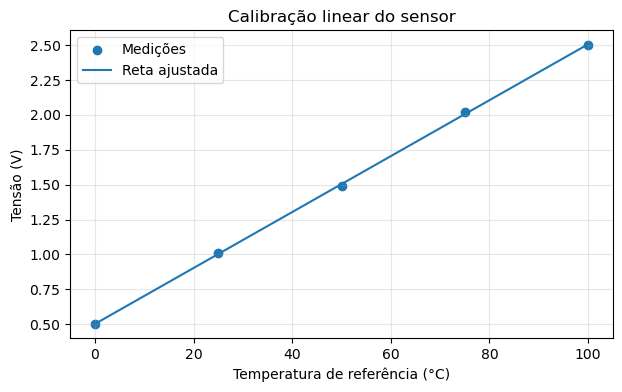

In [21]:
T_ref = np.array([0., 25., 50., 75., 100.])
V_medido = np.array([0.50, 1.01, 1.49, 2.02, 2.50])
a, b = np.polyfit(T_ref, V_medido, 1)
V_ajustado = a*T_ref+b
residuos_V = V_medido-V_ajustado
print(f"Sensibilidade = {a:.5f} V/°C; offset = {b:.4f} V")
print("Resíduos (V):", np.round(residuos_V, 4))
fig, ax = plt.subplots(figsize=(7,4))
ax.scatter(T_ref,V_medido,label="Medições")
ax.plot(T_ref,V_ajustado,label="Reta ajustada")
ax.set(xlabel="Temperatura de referência (°C)",ylabel="Tensão (V)",title="Calibração linear do sensor")
ax.grid(alpha=.3); ax.legend(); plt.show()

<div id="secao-6" style="background-color:#f1faff; border-left:6px solid #0074B7; color:#003366; border-radius:8px; padding:15px 20px; font-size:20px; font-weight:bold;">6. Erro, exatidão, precisão e incerteza</div>

**Erro, precisão e incerteza não são sinônimos.** O erro de indicação é a diferença entre o valor indicado e o valor de referência:

$$e=T_{indicado}-T_{referência}.$$

Se o padrão indica 80,0 °C e o instrumento indica 79,6 °C, o erro é $-0{,}4$ °C. A **exatidão** relaciona-se à proximidade do valor de referência; a **precisão** à dispersão entre medições repetidas. A **incerteza de medição** requer avaliação das contribuições pertinentes e não pode ser substituída apenas pelo erro observado.

Para verificar cálculos numéricos, `np.isclose` é útil, mas a tolerância deve refletir o problema.

In [22]:
T_referencia = 80.0
T_indicada = 79.6
erro_C = T_indicada-T_referencia
erro_relativo_pct = abs(erro_C)/abs(T_referencia)*100
print(f"Erro de indicação = {erro_C:+.2f} °C")
print(f"Erro relativo em módulo = {erro_relativo_pct:.2f}%")

Erro de indicação = -0.40 °C
Erro relativo em módulo = 0.50%


<div id="secao-7" style="background-color:#f1faff; border-left:6px solid #0074B7; color:#003366; border-radius:8px; padding:15px 20px; font-size:20px; font-weight:bold;">7. Análise estatística de medições repetidas</div>

**Controle de Qualidade — repetibilidade.** Cinco leituras hipotéticas de temperatura são 79,8; 80,1; 80,0; 79,9 e 80,2 °C. A média é

$$
 \bar T=\ \frac{1}{n}\\sum_{i=1}^n T_i=80{,}0 \ ^\circ \mathrm{C}.$$

O desvio-padrão amostral utiliza divisor $n-1$ (`ddof=1`). O erro-padrão da média é $s/ \sqrt{n}$, mas não representa automaticamente a incerteza total do instrumento.

In [23]:
leituras_C = np.array([79.8,80.1,80.0,79.9,80.2])
media_C = np.mean(leituras_C)
desvio_C = np.std(leituras_C,ddof=1)
erro_padrao_C = desvio_C/np.sqrt(leituras_C.size)
print(f"Média = {media_C:.3f} °C")
print(f"Desvio-padrão amostral = {desvio_C:.3f} °C")
print(f"Erro-padrão da média = {erro_padrao_C:.3f} °C")

Média = 80.000 °C
Desvio-padrão amostral = 0.158 °C
Erro-padrão da média = 0.071 °C


<div id="secao-8" style="background-color:#f1faff; border-left:6px solid #0074B7; color:#003366; border-radius:8px; padding:15px 20px; font-size:20px; font-weight:bold;">8. Ruído e geração de sinais sintéticos</div>

**Sinais e ruído.** Um sensor pode registrar uma temperatura real variável e, simultaneamente, flutuações eletrônicas e ambientais. No modelo didático,

$$
T_{medida}(t)=T_{real}(t)+\ \varepsilon(t)
$$

em que $ \varepsilon(t)$ representa ruído aditivo. Geraremos um sinal com tendência lenta e uma perturbação aleatória de média aproximadamente nula. Em uma instalação real, ruído pode ser correlacionado, apresentar interferências periódicas ou depender das condições operacionais.

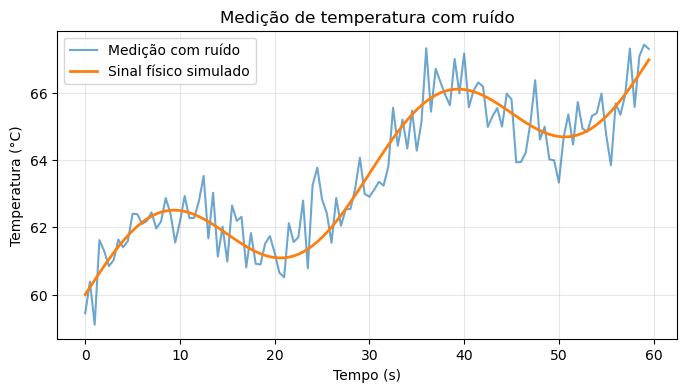

In [24]:
t = np.arange(0.,60.,0.5)
T_real = 60.0+0.12*t+1.5*np.sin(2*np.pi*t/30)
ruido = rng.normal(0.0,0.7,size=t.size)
T_ruidosa = T_real+ruido
fig,ax=plt.subplots(figsize=(8,4))
ax.plot(t,T_ruidosa,alpha=.65,label="Medição com ruído")
ax.plot(t,T_real,linewidth=2,label="Sinal físico simulado")
ax.set(xlabel="Tempo (s)",ylabel="Temperatura (°C)",title="Medição de temperatura com ruído")
ax.grid(alpha=.3);ax.legend();plt.show()

<div id="secao-9" style="background-color:#f1faff; border-left:6px solid #0074B7; color:#003366; border-radius:8px; padding:15px 20px; font-size:20px; font-weight:bold;">9. Filtragem por média móvel</div>

**Média móvel.** Uma forma simples de reduzir flutuações é substituir cada valor pela média de uma janela de $N$ amostras:

$$
\widehat T_k=\ \frac{1}{N}\ \sum_{j=0}^{N-1}T_{k-j}

$$

Para as leituras 70, 72 e 71 °C, a média é $(70+72+71)/3=71$°C. A média móvel **suaviza**, mas também introduz atraso e pode ocultar mudanças rápidas. Usaremos uma janela causal: somente a leitura atual e as anteriores entram no cálculo.

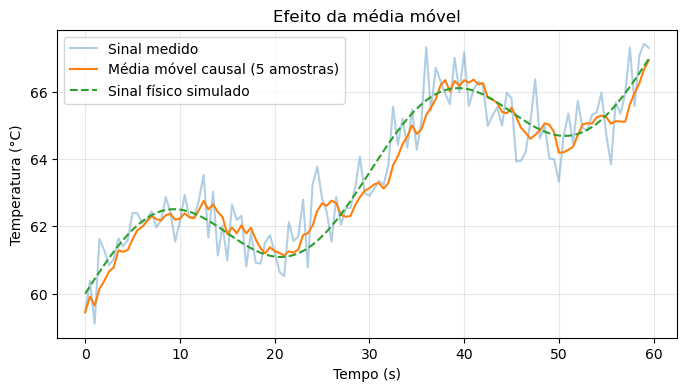

In [25]:
def media_movel_causal(x, janela):
    x=np.asarray(x,dtype=float)
    if janela < 1 or janela > len(x):
        raise ValueError("Janela inválida.")
    return np.array([np.mean(x[max(0,k-janela+1):k+1]) for k in range(len(x))])

T_movel = media_movel_causal(T_ruidosa,5)
fig,ax=plt.subplots(figsize=(8,4))
ax.plot(t,T_ruidosa,alpha=.35,label="Sinal medido")
ax.plot(t,T_movel,label="Média móvel causal (5 amostras)")
ax.plot(t,T_real,linestyle="--",label="Sinal físico simulado")
ax.set(xlabel="Tempo (s)",ylabel="Temperatura (°C)",title="Efeito da média móvel")
ax.grid(alpha=.3);ax.legend();plt.show()

<div id="secao-10" style="background-color:#f1faff; border-left:6px solid #0074B7; color:#003366; border-radius:8px; padding:15px 20px; font-size:20px; font-weight:bold;">10. Filtragem exponencial de primeira ordem</div>

**Filtro exponencial.** Um filtro digital de primeira ordem pode ser escrito como

$$
y_k=\ \alpha x_k+(1-\ \alpha)y_{k-1},\ \qquad 0<\ \alpha\ \leq1
$$

Se $x_k=80$ °C, $y_{k-1}=70$ °C e $\\alpha=0{,}2$, então $y_k=0{,}2(80)+0{,}8(70)=72$ °C. Valores menores de $\\alpha$ produzem suavização maior, porém resposta mais lenta. Este filtro não substitui a caracterização dinâmica do sensor.

Exemplo manual: 72.0 °C


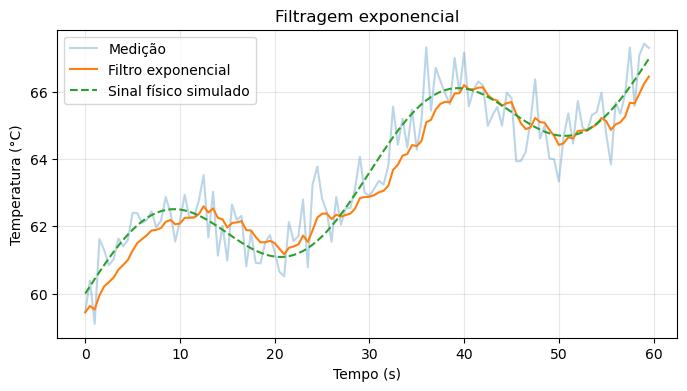

In [26]:
def filtro_exponencial(x,alpha):
    if not 0<alpha<=1:
        raise ValueError("Alpha deve estar em (0, 1].")
    x=np.asarray(x,dtype=float)
    y=np.empty_like(x)
    y[0]=x[0]
    for k in range(1,len(x)):
        y[k]=alpha*x[k]+(1-alpha)*y[k-1]
    return y

T_filtrada=filtro_exponencial(T_ruidosa,0.2)
print("Exemplo manual:",0.2*80+0.8*70,"°C")
fig,ax=plt.subplots(figsize=(8,4))
ax.plot(t,T_ruidosa,alpha=.3,label="Medição")
ax.plot(t,T_filtrada,label="Filtro exponencial")
ax.plot(t,T_real,linestyle="--",label="Sinal físico simulado")
ax.set(xlabel="Tempo (s)",ylabel="Temperatura (°C)",title="Filtragem exponencial")
ax.grid(alpha=.3);ax.legend();plt.show()

<div id="secao-11" style="background-color:#f1faff; border-left:6px solid #0074B7; color:#003366; border-radius:8px; padding:15px 20px; font-size:20px; font-weight:bold;">11. Tempo de amostragem e frequência de Nyquist</div>

**Amostragem e aliasing.** Para uma senoide de frequência $f$, o teorema de amostragem exige $f_s>2f$ para reconstrução ideal sob hipóteses apropriadas. Essa condição não é suficiente, por si só, para sinais que contenham componentes acima de $f_s/2$: na prática, é necessário limitar a banda antes da aquisição.

Uma senoide de 7 Hz amostrada a 10 Hz pode aparecer como uma oscilação de 3 Hz (**aliasing**). Vamos comparar as amostras com a onda contínua simulada.

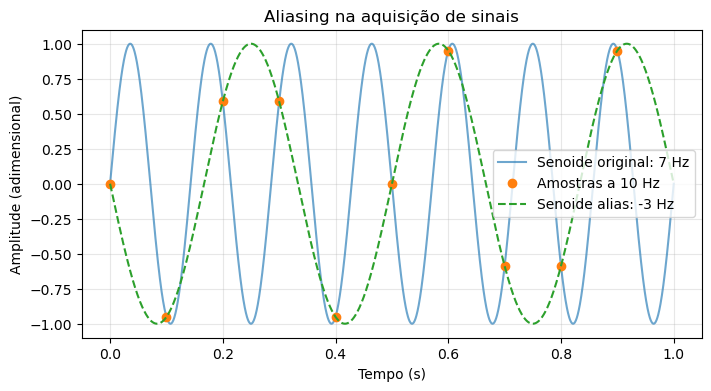

In [27]:
f_sinal=7.0
fs_amostragem=10.0
t_fino=np.linspace(0,1,2001)
t_amostras=np.arange(0,1,1/fs_amostragem)
s_fino=np.sin(2*np.pi*f_sinal*t_fino)
s_amostras=np.sin(2*np.pi*f_sinal*t_amostras)
fig,ax=plt.subplots(figsize=(8,4))
ax.plot(t_fino,s_fino,label="Senoide original: 7 Hz",alpha=.65)
ax.plot(t_amostras,s_amostras,"o",label="Amostras a 10 Hz")
ax.plot(t_fino,np.sin(2*np.pi*(-3)*t_fino),"--",label="Senoide alias: -3 Hz")
ax.set(xlabel="Tempo (s)",ylabel="Amplitude (adimensional)",title="Aliasing na aquisição de sinais")
ax.grid(alpha=.3);ax.legend();plt.show()

<div id="secao-12" style="background-color:#f1faff; border-left:6px solid #0074B7; color:#003366; border-radius:8px; padding:15px 20px; font-size:20px; font-weight:bold;">12. Resposta dinâmica de um sensor de temperatura</div>

**Dinâmica do sensor.** Um sensor de temperatura pode ser aproximado, sob hipóteses específicas, por um sistema de primeira ordem:

$$
\tau\ \frac{dT_m}{dt}+T_m=T_p
$$

em que $T_m$ é a indicação, $T_p$ a temperatura do processo e $\\tau$ a constante de tempo. Para um degrau de 20 para 80 °C,

$$
T_m(t)=80+(20-80)e^{-t/\ \tau}
$$

Com $\tau=5$ s, em $t=5$ s a indicação é aproximadamente 57,93°C, isto é, percorreu cerca de 63,2% da variação total. Atraso de medição não deve ser confundido com atraso físico do processo.

T(5 s) = 57.93 °C


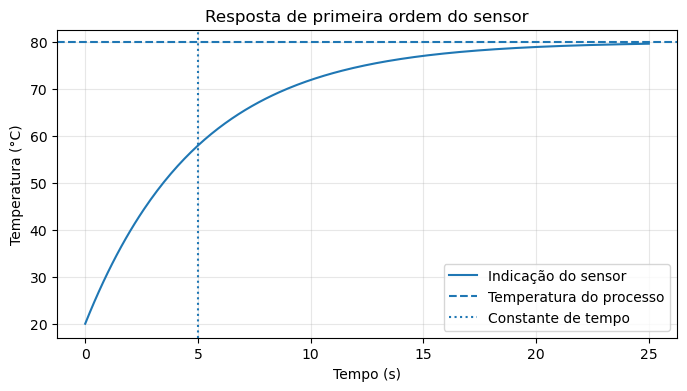

In [28]:
tau_s=5.0
t_sensor=np.linspace(0,25,251)
T_sensor=80+(20-80)*np.exp(-t_sensor/tau_s)
print(f"T(5 s) = {80-60*np.exp(-1):.2f} °C")
fig,ax=plt.subplots(figsize=(8,4))
ax.plot(t_sensor,T_sensor,label="Indicação do sensor")
ax.axhline(80,linestyle="--",label="Temperatura do processo")
ax.axvline(tau_s,linestyle=":",label="Constante de tempo")
ax.set(xlabel="Tempo (s)",ylabel="Temperatura (°C)",title="Resposta de primeira ordem do sensor")
ax.grid(alpha=.3);ax.legend();plt.show()

<div id="secao-13" style="background-color:#f1faff; border-left:6px solid #0074B7; color:#003366; border-radius:8px; padding:15px 20px; font-size:20px; font-weight:bold;">13. Detecção de valores anômalos e falhas</div>

**Falhas e valores anômalos.** Uma leitura muito diferente das demais pode resultar de uma perturbação real, falha de sensor, problema de transmissão ou erro de registro. Não devemos eliminar automaticamente valores extremos.

Um critério exploratório simples usa o desvio absoluto em relação à mediana. Neste exemplo, consideraremos um limite didático de 3 °C; ele **não** representa uma especificação industrial. As leituras sinalizadas devem ser investigadas antes de qualquer correção.

In [29]:
temperaturas_teste=np.array([70.0,70.2,69.9,70.1,85.0,70.0,70.3])
mediana=np.median(temperaturas_teste)
limite_didatico=3.0
suspeitos=np.abs(temperaturas_teste-mediana)>limite_didatico
print("Mediana:",mediana,"°C")
print("Leituras suspeitas:",temperaturas_teste[suspeitos])
print("Índices para investigação:",np.where(suspeitos)[0])

Mediana: 70.1 °C
Leituras suspeitas: [85.]
Índices para investigação: [4]


<div id="secao-14" style="background-color:#f1faff; border-left:6px solid #0074B7; color:#003366; border-radius:8px; padding:15px 20px; font-size:20px; font-weight:bold;">14. Controle de processos: referência, medição e erro</div>

**Controle de Processos Aplicado.** Em uma malha de controle, a temperatura medida é comparada à referência:

$$e_k=T_{SP}-T_{PV,k}.$$

Se $T_{SP}=80$ °C e $T_{PV}=76$ °C, o erro é $+4$ °C. Um filtro pode suavizar ruído, mas também atrasar a informação usada pelo controlador. Portanto, a escolha do filtro deve considerar a dinâmica da planta e da malha de controle.

In [30]:
T_SP=80.0
T_PV=np.array([74.,76.,78.,79.,80.,81.])
erro=T_SP-T_PV
print("Erros de controle (°C):",erro)
print(f"Erro absoluto médio: {np.mean(np.abs(erro)):.2f} °C")

Erros de controle (°C): [ 6.  4.  2.  1.  0. -1.]
Erro absoluto médio: 2.33 °C


<div id="secao-15" style="background-color:#f1faff; border-left:6px solid #0074B7; color:#003366; border-radius:8px; padding:15px 20px; font-size:20px; font-weight:bold;">15. Análise de sinais no domínio da frequência</div>

**Frequência e espectro.** A transformada discreta de Fourier decompõe um sinal amostrado em componentes de frequência. Para uma senoide de 2 Hz amostrada a 50 Hz, esperamos observar uma componente dominante próxima de 2 Hz.

A transformada rápida de Fourier (`np.fft.rfft`) é uma implementação eficiente da transformada discreta. O espectro deve ser interpretado com atenção à duração da observação, à resolução em frequência, à janela e à presença de ruído.

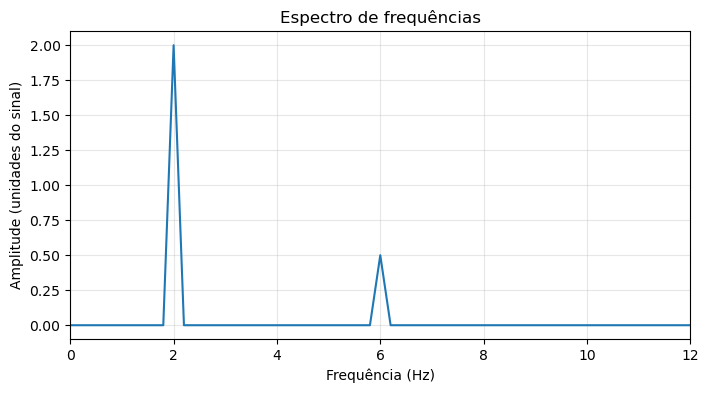

Frequência dominante: 2.0 Hz


In [31]:
fs_fft=50.0
duracao_s=5.0
t_fft=np.arange(0,duracao_s,1/fs_fft)
sinal=2*np.sin(2*np.pi*2*t_fft)+0.5*np.sin(2*np.pi*6*t_fft)
freq=np.fft.rfftfreq(len(sinal),d=1/fs_fft)
amplitude=2*np.abs(np.fft.rfft(sinal))/len(sinal)
amplitude[0]/=2
if len(sinal)%2==0:
    amplitude[-1]/=2
fig,ax=plt.subplots(figsize=(8,4))
ax.plot(freq,amplitude)
ax.set(xlim=(0,12),xlabel="Frequência (Hz)",ylabel="Amplitude (unidades do sinal)",title="Espectro de frequências")
ax.grid(alpha=.3);plt.show()
print("Frequência dominante:",freq[np.argmax(amplitude)],"Hz")

<div id="secao-16" style="background-color:#f1faff; border-left:6px solid #0074B7; color:#003366; border-radius:8px; padding:15px 20px; font-size:20px; font-weight:bold;">16. Tratamento de dados experimentais com Pandas</div>

**Tratamento de dados com Pandas.** Um histórico de instrumentação pode ser organizado em uma tabela com instante, temperatura, pressão e estado de validade. Essa estrutura facilita o rastreamento das leituras e a exportação de relatórios.

Neste exemplo, os dados são gerados em memória. Em uma aplicação real, o arquivo exportado deve conter metadados suficientes para identificar instrumentos, unidades, calibração, período de aquisição e tratamento aplicado.

In [32]:
historico=pd.DataFrame({
    "tempo_s":t[:12],
    "temperatura_C":T_ruidosa[:12],
    "temperatura_filtrada_C":T_filtrada[:12],
})
historico["desvio_filtragem_C"]=historico["temperatura_C"]-historico["temperatura_filtrada_C"]
print(historico.head().round(3).to_string(index=False))
print("Média das 12 leituras:",round(historico["temperatura_C"].mean(),3),"°C")

 tempo_s  temperatura_C  temperatura_filtrada_C  desvio_filtragem_C
     0.0         59.445                  59.445               0.000
     0.5         60.385                  59.633               0.752
     1.0         59.104                  59.527              -0.423
     1.5         61.621                  59.946               1.675
     2.0         61.297                  60.216               1.081
Média das 12 leituras: 61.096 °C


<div id="secao-17" style="background-color:#f1faff; border-left:6px solid #0074B7; color:#003366; border-radius:8px; padding:15px 20px; font-size:20px; font-weight:bold;">17. Projeto integrador: supervisão de um tanque aquecido</div>

**Projeto integrador — supervisão de um tanque aquecido.** Considere um tanque bem misturado com temperatura real crescente. Um transmissor ideal de 4 a 20 mA representa 0 a 100 °C. O sinal de corrente é adquirido com ruído e convertido novamente para temperatura.

Para $T=75$ °C, o cálculo manual fornece

$$
I=4+16\ \frac{75}{100}=16\ \ \mathrm{mA}
$$

Vamos construir uma cadeia computacional completa: processo → corrente → aquisição com ruído → conversão → filtragem → avaliação do erro. O modelo é didático e não substitui projeto de instrumentação, análise de riscos ou procedimentos de segurança.

Corrente para 75 °C: 16.0 mA
Erro médio absoluto de aquisição: 0.449 °C


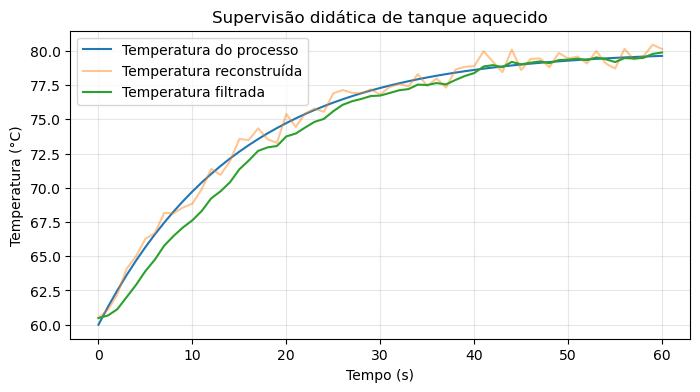

In [33]:
tempo_tanque=np.arange(0,61,1,dtype=float)
T_processo=60+20*(1-np.exp(-tempo_tanque/15))
I_ideal=4+16*T_processo/100
I_adquirida=I_ideal+rng.normal(0,0.07,size=I_ideal.size)
T_reconstruida=(I_adquirida-4)*100/16
T_supervisao=filtro_exponencial(T_reconstruida,0.3)
erro_instrumentacao=T_reconstruida-T_processo
print("Corrente para 75 °C:",4+16*75/100,"mA")
print(f"Erro médio absoluto de aquisição: {np.mean(np.abs(erro_instrumentacao)):.3f} °C")
fig,ax=plt.subplots(figsize=(8,4))
ax.plot(tempo_tanque,T_processo,label="Temperatura do processo")
ax.plot(tempo_tanque,T_reconstruida,alpha=.45,label="Temperatura reconstruída")
ax.plot(tempo_tanque,T_supervisao,label="Temperatura filtrada")
ax.set(xlabel="Tempo (s)",ylabel="Temperatura (°C)",title="Supervisão didática de tanque aquecido")
ax.grid(alpha=.3);ax.legend();plt.show()

<div id="secao-18" style="background-color:#f1faff; border-left:6px solid #0074B7; color:#003366; border-radius:8px; padding:15px 20px; font-size:20px; font-weight:bold;">18. Boas práticas e validação de resultados</div>

**Validação de engenharia.** Antes de aceitar um resultado, verifique as unidades, os limites físicos, a faixa do instrumento, o tempo de amostragem e a coerência da dinâmica. Um filtro não corrige necessariamente uma calibração incorreta. Um algoritmo de detecção não substitui o diagnóstico de uma falha.

O `assert` pode ajudar a testar hipóteses de desenvolvimento, como a conversão de 12 mA em 5 bar, mas não deve ser usado como proteção operacional obrigatória, pois pode ser desativado pelo Python em modo otimizado. Para entradas inválidas, utilize verificações explícitas com `if` e exceções adequadas.

In [34]:
assert np.isclose(corrente_para_pressao(4),0)
assert np.isclose(corrente_para_pressao(20),10)
assert np.isclose(np.mean(leituras_C),80)
assert np.isfinite(T_supervisao).all()
print("Testes didáticos de consistência aprovados.")

Testes didáticos de consistência aprovados.


<div id="secao-19" style="background-color:#f1faff; border-left:6px solid #0074B7; color:#003366; border-radius:8px; padding:15px 20px; font-size:20px; font-weight:bold;">19. Exercícios de consolidação</div>

**Exercício 1 — Instrumentação.** Um transmissor de nível fornece 4 a 20 mA para 0 a 5 m. Converta as leituras 4, 7,2, 12 e 20 mA em nível. Resolva manualmente o caso de 12 mA.

**Exercício 2 — Calibração.** Um sensor fornece 0,4 V a 0 °C e 2,4 V a 100 °C. Determine manualmente a sensibilidade e o offset. Construa uma função Python que converta tensão em temperatura.

**Exercício 3 — Metrologia.** Para as leituras 49,8; 50,1; 50,0; 49,9 e 50,2 °C, calcule média, desvio-padrão amostral e erro de indicação em relação a 50 °C. Explique a diferença entre erro e incerteza.

**Exercício 4 — Filtragem.** Aplique uma média móvel causal de três amostras à sequência 70, 72, 71, 75, 74 °C. Calcule manualmente a saída da terceira amostra.

**Exercício 5 — Filtro exponencial.** Para $\\alpha=0{,}25$, $y_0=60$ °C e leituras 60, 68, 72 e 80 °C, calcule os três primeiros passos e compare a saída filtrada com a original.

**Exercício 6 — Amostragem.** Uma vibração possui componente de 12 Hz. Discuta se a amostragem a 20 Hz é suficiente e proponha uma frequência de aquisição acompanhada de justificativa.

**Exercício 7 — Dinâmica.** Um sensor de primeira ordem tem $\\tau=8$ s e sofre um degrau de 20 para 100 °C. Calcule manualmente a indicação em $t=8$ s e gere o gráfico até 40 s.

**Exercício 8 — Controle.** Considere $T_{SP}=90$ °C e medições de 84, 87, 89, 91 e 90 °C. Calcule o vetor de erros e o erro absoluto médio.

**Desafio integrador.** Simule um transmissor de pressão com ruído, um filtro exponencial e uma mudança rápida de pressão. Compare o atraso introduzido pelo filtro e discuta os riscos de interpretar a leitura filtrada como resposta instantânea do processo.

<div id="secao-20" style="background-color:#f1faff; border-left:6px solid #0074B7; color:#003366; border-radius:8px; padding:15px 20px; font-size:20px; font-weight:bold;">20. Conclusões</div>

Neste notebook, relacionamos grandezas físicas, sensores, transmissores, amostragem e tratamento computacional de sinais. A conversão de unidades e a calibração permitem interpretar as medições; a análise estatística e a filtragem ajudam a compreender sua variabilidade; a resposta dinâmica e a análise de frequência revelam limitações importantes da aquisição.

A principal conclusão é que **medir não é apenas registrar números**. Uma medição de Engenharia precisa ser interpretada à luz do fenômeno físico, do instrumento, do modelo de conversão e das limitações do processamento. Esse conhecimento prepara o estudo de controle e simulação de processos.

<div style="text-align: center; font-size: 12px; color: gray; margin-top: 40px; padding-top: 15px; border-top: 1px solid #dddddd;">
Material desenvolvido pelo Grupo de Pesquisas em Modelagem Computacional da UESC.<br>
© 2026 — Todos os direitos reservados. Uso comercial somente mediante autorização.
</div>